Termolab python


1.) Beregn massestrømmen av kuldemedia $\dot{m}, [\frac{kg}{s}]$, for hver målingsserie dere har registrert ved å bruke energibalansen til et åpent system:

$$
\dot{W}_{komp} = \dot{m}(h_{inn}-h_{ut})
$$
 
som gir oss
$$
\frac{\dot{W}_{komp}}{(h_{inn}-h_{ut})} = \dot{m}
$$
hvor 
$$
h_{ut} = h_{inn} + \frac{h_{2,is}-h_{inn}}{\eta_{is}}
$$
og 
$$
\eta_{is} = 0.0017\pi^3 - 0.0286\pi^2 + 0.1533\pi + 0.1642
$$
$$
\pi = \frac{p_{kondenser}}{p_{fordamper}}
$$

In [1]:
import pandas as pd
import numpy as np

# m trenger: W, h_inn, h_ut, 
# h_ut trenger: h_inn, h_2,is, eta_is
# eta_is trenger: p_kond, p_ford
# p_kond, p_ford trenger: t_kond, t_ford
# h_2,is trenger: 

df = pd.read_excel("merged log termo.xlsx", sheet_name="log")  

df.columns = ["time", "T1", "T2", "T3", "T4", "Thot", "Tcold", "W_komp", "Tkond", "Tford"]   
            #hh:mm:ss, degC,, degC, degC, degC, degC, degC,      W,       degC,    degC 
# finner W
W_komp = df["W_komp"].to_numpy()


In [2]:
from CoolProp.CoolProp import PropsSI

fluid = "R134a"
kelvin = 273.15
manual_tid= ["12:24:01", "12:25:59", "12:28:08", "12:30:06", "12:32:04"]

log_date = df["time"].dt.date.iloc[0]

start_time, end_time = pd.to_datetime([
    f"{log_date} {manual_tid[0]}",
    f"{log_date} {manual_tid[-1]}"])

manual_data = df.loc[df["time"].between(start_time, end_time)].copy()

#planen var å bruke  en fuknsjon til å fikse alle  data, men det er for stor variasjon i demands
def entalpi(data, Ta, Tb):
    
    """
    input: data -> dataset
    Ta er første temperatur, Tb er andre temperatur
    
    1. lager kopi av dataset
    2. finner fordampnings- og konsenseringstrykk
    3. bruker trykkene for å finne den isentropiske virkningsgraden
    4. finenr h1, h2, h2is ved hjelp av dataene i forrige steg
    5. returnerer dataset med original data + nye entalpier
    """

    data = data.copy()
    T_suc  = data[Ta].to_numpy() + kelvin   # [K]
    p_ford = PropsSI("P", "T", data["Tford"].to_numpy() + kelvin, "Q", 1, fluid)   # [Pa]
    p_kond = PropsSI("P", "T", data["Tkond"].to_numpy() + kelvin, "Q", 1, fluid)   # [Pa]

    data["superheat_K"] = data[Ta] - data[Tb]            
    data["pi"] = p_kond / p_ford
    pi = data["pi"]
    data["eta_is"] = 0.0017*pi**3 - 0.0286*pi**2 + 0.1533*pi + 0.1642

    h1   = PropsSI("H", "T", T_suc, "P", p_ford, fluid)       # [J/kg]
    s1   = PropsSI("S", "T", T_suc, "P", p_ford, fluid)       # [J/kgK]
    h2is = PropsSI("H", "P", p_kond, "S", s1, fluid)          # isentropisk 
    h2   = h1 + (h2is - h1) / data["eta_is"].to_numpy()       # ekte

    data["h1"], data["h2is"], data["h2"] = h1, h2is, h2       # [J/kg]
    return data

resultat_komp = entalpi(manual_data, "T1", "Tkond")
res_manual_komp = resultat_komp[resultat_komp["time"].dt.strftime("%H:%M:%S").isin(manual_tid)]
print(res_manual_komp[["time", "eta_is", "h1", "h2", "h2is"]])

                  time    eta_is             h1             h2           h2is
27 2026-10-06 12:24:01  0.396674  423448.046318  477115.550893  444736.562076
38 2026-10-06 12:25:59  0.411898  427709.421687  489917.418805  453332.749961
50 2026-10-06 12:28:08  0.421804  432295.215675  502613.469525  461955.740381
61 2026-10-06 12:30:06  0.428598  435674.298241  515587.507109  469924.934773
72 2026-10-06 12:32:04  0.429792  438680.891418  524540.959219  475582.827625


In [3]:
resultat_komp["m_dot"] = resultat_komp["W_komp"] / (resultat_komp["h2"] - resultat_komp["h1"])     # [kg/s]
resultat_komp["m_dot_e3"] = resultat_komp["m_dot"] * 1e3                        # [1e-3 kg/s]

res_manual_komp2 = resultat_komp[resultat_komp["time"].dt.strftime("%H:%M:%S").isin(manual_tid)]

print(res_manual_komp2["m_dot"])

27    0.002739
38    0.002395
50    0.002147
61    0.001915
72    0.001817
Name: m_dot, dtype: float64


2. Beregne varmeytelse av kondensator i $Q_{kond}$, [W], for hver målingsserie dere har tatt ved å
bruke energibalansen til et åpent system:


$$
\dot{Q}_{kond} = \dot{m}(h_{ut}-h_{inn})
$$

$
h_{inn} – \text{ entalpien inn på kondensator}, [\frac{J}{kg}]$
, bruk T2 temperaturen og kondenseringstrykk $p_{kond}$.

$h_{ut} - \text{ entalpien ut av kondensator} , [\frac{J}{kg}]$
,bruk kondenseringstrykk, $p_{kond}$, og T3 temperaturen.

For å kompensere for varmetap mellom rør og omgivelsestemperaturen til kondensatoren, så
anbefales det at dere legger til 4.8 K til temperaturverdiene I T3 og T2.
Altså at dere tar:
Temperatur T3 = T3 + 4.8 K (VIKTIG: koeffisienten brukes ikke hvis T3 + 4.8 K> metnings
temperatur).
Temperatur T2 = T2 + 4.8 K

In [4]:
def entalpi_kond(data, korr=4.8):
    data = data.copy()
    p_kond = PropsSI("P", "T", data["Tkond"].to_numpy() + kelvin, "Q", 1, fluid)  
    T3 = data["T3"].to_numpy()
    T3c = np.where(T3 + korr < data["Tkond"].to_numpy(), T3 + korr, T3)           
    data["hut_kond"] = PropsSI("H", "T", T3c + kelvin, "P", p_kond, fluid)
    data["hinn_kond"] = data["h2"]        
    return data

res_kond = entalpi_kond(resultat_komp)
res_kond["Qdot_kond"] = res_kond["m_dot"] * abs((res_kond["hinn_kond"] - res_kond["hut_kond"]))

res_kond_man= res_kond[res_kond["time"].dt.strftime("%H:%M:%S").isin(manual_tid)]

print(res_kond_man[["time","Qdot_kond"]])


                  time   Qdot_kond
27 2026-10-06 12:24:01  610.529399
38 2026-10-06 12:25:59  547.550563
50 2026-10-06 12:28:08  501.809643
61 2026-10-06 12:30:06  461.169347
72 2026-10-06 12:32:04  444.600950


3.
Beregne varmeytelse av fordamper i $\dot{Q}_{ford}$, [𝑊] for hver målingsserie dere har registrert
ved å bruke energibalansen til et åpent system:
𝑄̇
𝑓𝑜𝑟𝑑 = 𝑚̇ (ℎ𝑢𝑡 − ℎ𝑖𝑛𝑛)
hinn – entalpien inn på fordamper , [
𝐽
𝑘𝑔], bruk entalpien i punkt 3 ettersom at entalpien ikke
endres etter ekspansjon.
TEP 4120 Semesteroppgave
18
hut - entalpien ut av fordamper , [
𝐽
𝑘𝑔], bruk fordampingstrykk, Pford, og T1.

In [5]:
def entalpi_ford(data, korr=4.8):
    data = data.copy()
    p_ford = PropsSI("P", "T", data["Tford"].to_numpy() + kelvin, "Q", 1, fluid)  
    T1 = data["T1"].to_numpy()
    data["hut_ford"]  = PropsSI("H", "T", T1 + kelvin, "P", p_ford, fluid)
    data["hinn_ford"] = data["hut_kond"]

    return data

res_ford = entalpi_ford(res_kond)
res_ford["Qdot_ford"] = res_ford["m_dot"] * abs((res_ford["hinn_ford"] - res_ford["hut_ford"]))

res_ford_man= res_ford[res_ford["time"].dt.strftime("%H:%M:%S").isin(manual_tid)]

print(res_ford_man[["time","Qdot_ford"]])

                  time   Qdot_ford
27 2026-10-06 12:24:01  463.529399
38 2026-10-06 12:25:59  398.550563
50 2026-10-06 12:28:08  350.809643
61 2026-10-06 12:30:06  308.169347
72 2026-10-06 12:32:04  288.600950


In [6]:
#test; Qford + Wkomp = Qkond:

print(res_ford_man["Qdot_ford"] + res_ford_man["W_komp"] == res_ford_man["Qdot_kond"]) 
print("yay")

27    True
38    True
50    True
61    True
72    True
dtype: bool
yay


4. Beregne effektfaktor av varmepumpe: COPvarmepumpe for hver av målingsserie. Plott
COPvarmepumpe per tid.

In [7]:
res_ford_man["COP_HP"] = res_ford_man["Qdot_kond"] / res_ford_man["W_komp"]

print(res_ford_man[["time","COP_HP"]])

                  time    COP_HP
27 2026-10-06 12:24:01  4.153261
38 2026-10-06 12:25:59  3.674836
50 2026-10-06 12:28:08  3.323243
61 2026-10-06 12:30:06  3.014179
72 2026-10-06 12:32:04  2.850006


C:\Users\filip\AppData\Local\Temp\ipykernel_30580\3695118700.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  res_ford_man["COP_HP"] = res_ford_man["Qdot_kond"] / res_ford_man["W_komp"]


5.
Plott 𝑄̇
𝑘𝑜𝑛𝑑, 𝑄̇
𝑓𝑜𝑟𝑑, 𝑊̇
𝑘𝑜𝑚𝑝 og massetrømmen av R134a, 𝑚̇ , per tid (sec eller min). Bruk
absolutte verdier for plotting

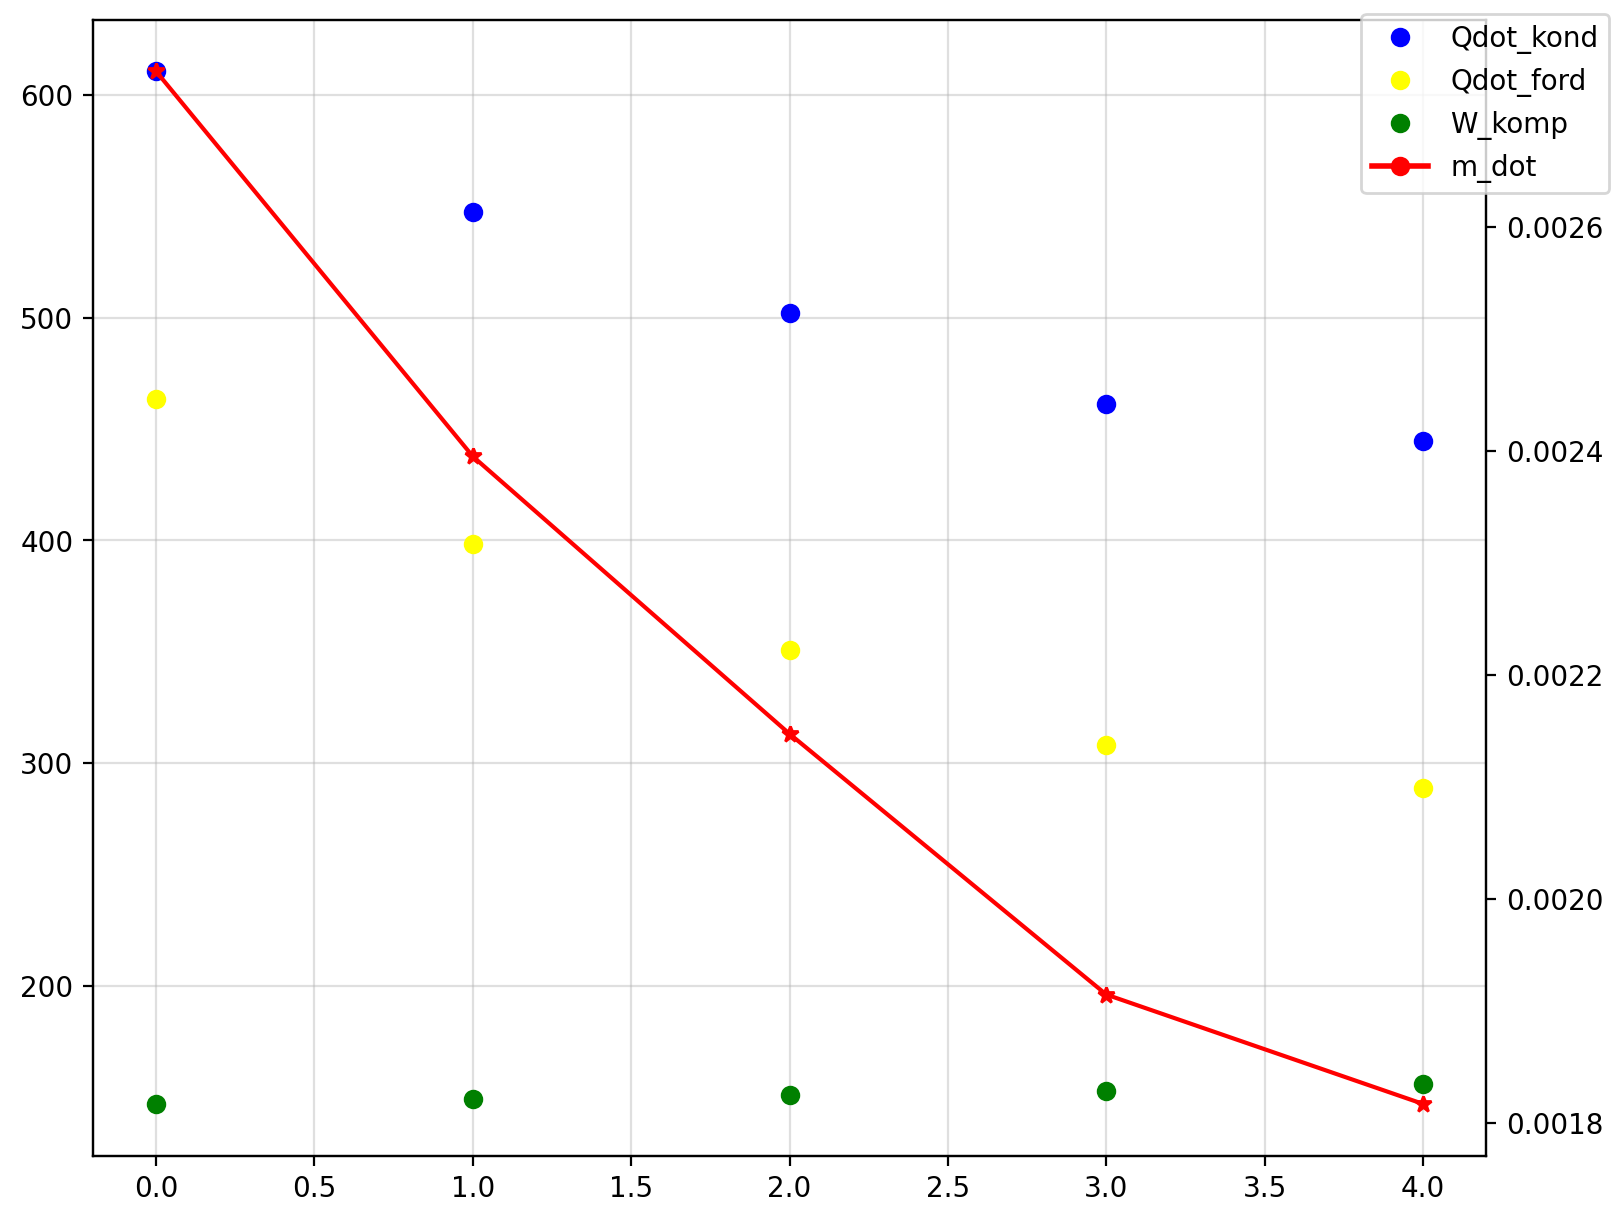

In [8]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

x = range(len(res_ford_man["Qdot_kond"]))

fig, ax1 = plt.subplots(figsize=(8,6), dpi=200, layout="constrained")
ax2 = ax1.twinx()


ax1.plot(x,res_ford_man["Qdot_kond"],"o", label = "Qdot_kond", color="blue" )
ax1.plot(x,res_ford_man["Qdot_ford"],"o", label = "Qdot_ford", color="yellow" )
ax1.plot(x,res_ford_man["W_komp"],"o", label = "W_komp", color="green")
ax2.plot(x,res_ford_man["m_dot"], "-*", label = "m_dot", color="red" )

ax1.grid(alpha = 0.4)

handles = [
    Line2D([], [], ls="", marker="o",  color="blue",   label="Qdot_kond"),
    Line2D([], [], ls="", marker="o",  color="yellow", label="Qdot_ford"),
    Line2D([], [], ls="", marker="o",  color="green",   label="W_komp"),
    Line2D([], [], ls="-", lw=2, marker="o",  color="red", label="m_dot"),
]
fig.legend(handles=handles, loc="upper right")
 


plt.show()


7. Beregn total varme Qkond , [𝑊ℎ], som er produsert i løpet av målingene. Bruk to metoder:
• 𝑄𝑘𝑜𝑛𝑑 = ∑ 𝑄̅̇
𝑘𝑜𝑛𝑑
𝑛
𝑛=1 ∗ 𝜏
𝑄̅̇
𝑘𝑜𝑛𝑑– varmeytelse, gjennomsnitt verdien av to målinger, [𝑊].
τ – tidsintervall mellom de målingene, [𝑡𝑖𝑚𝑒𝑟].
• 𝑄𝑘𝑜𝑛𝑑 = (𝑐𝑝,𝑣𝑎𝑛𝑛 ∗ 𝑚𝑣𝑎𝑛𝑛 + 630) ∗ (𝑇𝑒𝑛𝑑 − 𝑇0
)/3600
𝑐𝑝,𝑣𝑎𝑛𝑛 – varmekapasitet av vann, 4200 , [
𝐽
𝑘𝑔𝐾],
𝑚𝑣𝑎𝑛𝑛 – vekt av vann, kg,
630 – korrelasjon for oppvarming av tank, [
𝐽
𝐾
],
𝑇𝑒𝑛𝑑 𝑜𝑔 𝑇0 – Vanntemperaturen på siste og første målepunkt, [℃].


In [13]:
#metode 1:

m = res_ford_man.copy()                      
m["Qdot_kond"] = m["Qdot_kond"].abs()           
t   = (m["time"] - m["time"].iloc[0]).dt.total_seconds().to_numpy()

tau = np.diff(t) / 3600                         
Q   = m["Qdot_kond"].to_numpy()
Qbar = (Q[:-1] + Q[1:]) / 2                     
Qkond_Wh = np.sum(Qbar * tau)                   
print(round(Qkond_Wh,5), "Wh")

68.40741 Wh
